# Brain Tumor MRI Classification — CNN (Transfer Learning)

Classifies MRI scans into **glioma, meningioma, pituitary, notumor**.

**Before running:** Runtime → Change runtime type → select **GPU** (T4 is fine).

This notebook expects your dataset zipped with this structure inside:
```
Training/glioma/*.jpg
Training/meningioma/*.jpg
Training/notumor/*.jpg
Training/pituitary/*.jpg
Testing/glioma/*.jpg
Testing/meningioma/*.jpg
Testing/notumor/*.jpg
Testing/pituitary/*.jpg
```

## 1. Check GPU

In [ ]:
import torch
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: no GPU detected — go to Runtime > Change runtime type > GPU')

CUDA available: True
GPU: Tesla T4


## 2. Install dependencies

In [ ]:
!pip install -q torch torchvision scikit-learn matplotlib pillow

## 3. Upload and unzip your dataset

Zip your `Training/` and `Testing/` folders together into one file (e.g. `archive.zip`) before uploading, so the structure matches what's described above.

In [ ]:
from google.colab import files
uploaded = files.upload()  # select your archive.zip

Saving archive.zip to archive.zip


In [ ]:
import zipfile, os, glob

zip_name = list(uploaded.keys())[0]
os.makedirs('data', exist_ok=True)
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('data')

# Sanity check: print class folders found
for split in ['Training', 'Testing']:
    root = os.path.join('data', split)
    if os.path.isdir(root):
        for cls in sorted(os.listdir(root)):
            n = len(glob.glob(os.path.join(root, cls, '*')))
            print(split, cls, n)

Training glioma 1400
Training meningioma 1400
Training notumor 1400
Training pituitary 1400
Testing glioma 400
Testing meningioma 400
Testing notumor 400
Testing pituitary 400


If the folder names above don't say `Training`/`Testing` directly (e.g. there's an extra nested folder from the zip), adjust `DATA_DIR` in the next section accordingly — print `os.listdir('data')` to check.

## 4. Imports and config

In [ ]:
import copy, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import KFold
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

DATA_DIR = 'data'      # change if your extracted folder is nested differently
BACKBONE = 'resnet18'  # or 'efficientnet_b0'
EPOCHS = 15
BATCH_SIZE = 32
LR = 3e-4
IMG_SIZE = 224
K_FOLDS = 5            # Added for 5-fold cross validation
PATIENCE = 3           # Added for Early Stopping

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


## 5. Model definition

In [ ]:
def build_model(backbone: str, num_classes: int = 4):
    """Transfer-learning model: pretrained ImageNet backbone + new classifier head."""
    if backbone == 'resnet18':
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        in_feats = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_feats, num_classes),
        )
    elif backbone == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        in_feats = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_feats, num_classes),
        )
    else:
        raise ValueError(f'Unknown backbone: {backbone}')
    return model

## 6. Data loading

In [ ]:
def get_dataloaders_cv(data_dir, img_size=224, batch_size=32, num_workers=2):
    mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats

    train_tf = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),  # MRI is grayscale; replicate to 3ch
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(p=0.3),
        transforms.RandomRotation(10),
        transforms.ColorJitter(brightness=0.15, contrast=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    eval_tf = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    full_train_dataset = datasets.ImageFolder(f'{data_dir}/Training', transform=train_tf)
    full_val_dataset = datasets.ImageFolder(f'{data_dir}/Training', transform=eval_tf)
    test_set = datasets.ImageFolder(f'{data_dir}/Testing', transform=eval_tf)

    assert full_train_dataset.classes == test_set.classes, 'Train/Test class order mismatch!'

    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    return full_train_dataset, full_val_dataset, test_loader, full_train_dataset.classes

full_train_dataset, full_val_dataset, test_loader, classes = get_dataloaders_cv(
    DATA_DIR, img_size=IMG_SIZE, batch_size=BATCH_SIZE
)
print('Classes:', classes)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
class EarlyStopping:
    def __init__(self, patience=3, delta=0.001):
        self.patience = patience
        self.delta = delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.delta:
            self.counter += 1
            print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

## 7. Training loop

In [ ]:
def train_cv(full_train_ds, full_val_ds, backbone, classes, device, k_folds=5, epochs=15, lr=3e-4, patience=3):
    kfold = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    overall_best_acc = 0.0
    overall_best_state = None
    best_fold_history = None

    for fold, (train_ids, val_ids) in enumerate(kfold.split(full_train_ds)):
        print(f'\n========== FOLD {fold + 1}/{k_folds} ==========')

        train_sub = Subset(full_train_ds, train_ids)
        val_sub = Subset(full_val_ds, val_ids)

        train_loader = DataLoader(train_sub, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
        val_loader = DataLoader(val_sub, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

        model = build_model(backbone, num_classes=len(classes)).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
        early_stopping = EarlyStopping(patience=patience)

        history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
        fold_best_acc = 0.0

        for epoch in range(epochs):
            t0 = time.time()
            model.train()
            running_loss, running_correct, n = 0.0, 0, 0
            for imgs, labels in train_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                optimizer.zero_grad()
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * imgs.size(0)
                running_correct += (outputs.argmax(1) == labels).sum().item()
                n += imgs.size(0)
            train_loss, train_acc = running_loss / n, running_correct / n

            model.eval()
            v_loss, v_correct, vn = 0.0, 0, 0
            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs, labels = imgs.to(device), labels.to(device)
                    outputs = model(imgs)
                    loss = criterion(outputs, labels)
                    v_loss += loss.item() * imgs.size(0)
                    v_correct += (outputs.argmax(1) == labels).sum().item()
                    vn += imgs.size(0)
            val_loss, val_acc = v_loss / vn, v_correct / vn
            scheduler.step(val_acc)

            history['train_loss'].append(train_loss)
            history['val_loss'].append(val_loss)
            history['train_acc'].append(train_acc)
            history['val_acc'].append(val_acc)

            if val_acc > fold_best_acc:
                fold_best_acc = val_acc
                if fold_best_acc > overall_best_acc:
                    overall_best_acc = fold_best_acc
                    overall_best_state = copy.deepcopy(model.state_dict())
                    best_fold_history = copy.deepcopy(history)

            print(f'Epoch {epoch+1:2d}/{epochs} | '
                  f'train_loss {train_loss:.4f} acc {train_acc:.4f} | '
                  f'val_loss {val_loss:.4f} acc {val_acc:.4f} | '
                  f'{time.time()-t0:.1f}s')

            # Early Stopping Check
            early_stopping(val_loss)
            if early_stopping.early_stop:
                print(f"Early stopping triggered at epoch {epoch+1}")
                break

    # Load overall best model across all folds
    best_model = build_model(backbone, num_classes=len(classes)).to(device)
    best_model.load_state_dict(overall_best_state)
    return best_model, best_fold_history, overall_best_acc

model, history, best_val_acc = train_cv(
    full_train_dataset, full_val_dataset, BACKBONE, classes, device,
    k_folds=K_FOLDS, epochs=EPOCHS, lr=LR, patience=PATIENCE
)
print(f'\nBest validation accuracy across all folds: {best_val_acc:.4f}')


========== FOLD 1/5 ==========
Epoch  1/15 | train_loss 0.2972 acc 0.8904 | val_loss 0.2015 acc 0.9393 | 40.3s
Epoch  2/15 | train_loss 0.1276 acc 0.9540 | val_loss 0.0761 acc 0.9750 | 37.6s
Epoch  3/15 | train_loss 0.0875 acc 0.9717 | val_loss 0.0761 acc 0.9768 | 38.8s
EarlyStopping counter: 1 out of 3
Epoch  4/15 | train_loss 0.0883 acc 0.9703 | val_loss 0.0663 acc 0.9741 | 37.6s
Epoch  5/15 | train_loss 0.0524 acc 0.9817 | val_loss 0.0783 acc 0.9804 | 36.4s
EarlyStopping counter: 1 out of 3
Epoch  6/15 | train_loss 0.0581 acc 0.9815 | val_loss 0.1865 acc 0.9446 | 37.9s
EarlyStopping counter: 2 out of 3
Epoch  7/15 | train_loss 0.0454 acc 0.9866 | val_loss 0.0920 acc 0.9670 | 37.5s
EarlyStopping counter: 3 out of 3
Early stopping triggered at epoch 7

========== FOLD 2/5 ==========
Epoch  1/15 | train_loss 0.2934 acc 0.8908 | val_loss 0.1763 acc 0.9295 | 38.1s
Epoch  2/15 | train_loss 0.1334 acc 0.9556 | val_loss 0.0838 acc 0.9777 | 37.4s
Epoch  3/15 | train_loss 0.0804 acc 0.9743 |

## 8. Evaluate on the held-out test set

In [ ]:
def evaluate(model, test_loader, device, classes):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    report = classification_report(all_labels, all_preds, target_names=classes, digits=3)
    cm = confusion_matrix(all_labels, all_preds)
    return acc, report, cm

acc, report, cm = evaluate(model, test_loader, device, classes)
print(f'Test accuracy: {acc:.4f}\n')
print(report)

Test accuracy: 0.9537

              precision    recall  f1-score   support

      glioma      1.000     0.830     0.907       400
  meningioma      0.908     0.985     0.945       400
     notumor      0.930     1.000     0.964       400
   pituitary      0.990     1.000     0.995       400

    accuracy                          0.954      1600
   macro avg      0.957     0.954     0.953      1600
weighted avg      0.957     0.954     0.953      1600



## 9. Plots

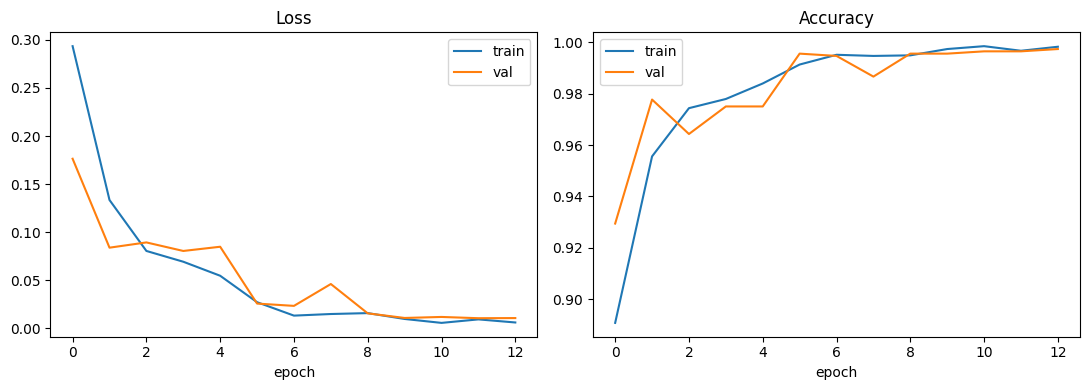

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='val')
axes[0].set_title('Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(history['train_acc'], label='train')
axes[1].plot(history['val_acc'], label='val')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

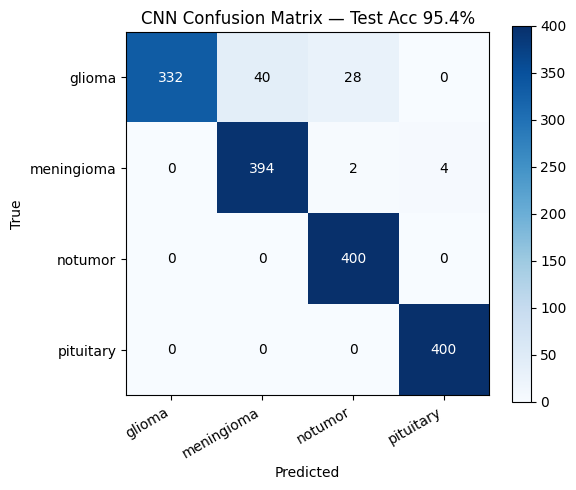

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=30, ha='right')
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title(f'CNN Confusion Matrix — Test Acc {acc:.1%}')
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

## 10. Save the model + download results

In [ ]:
torch.save({'model_state': model.state_dict(), 'classes': classes, 'backbone': BACKBONE},
           'best_model.pt')
with open('classification_report.txt', 'w') as f:
    f.write(f'Test accuracy: {acc:.4f}\n\n{report}')

print('Saved: best_model.pt, training_curves.png, confusion_matrix.png, classification_report.txt')

Saved: best_model.pt, training_curves.png, confusion_matrix.png, classification_report.txt


In [ ]:
from google.colab import files
files.download('best_model.pt')
files.download('confusion_matrix.png')
files.download('training_curves.png')
files.download('classification_report.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Predict on a new image

Run this cell after training (or after re-loading `best_model.pt`) to classify a single new MRI.

In [ ]:
import torch.nn.functional as F
from PIL import Image

def predict_image(image_path, model, classes, img_size=224, device='cpu'):
    mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    tf = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])
    img = Image.open(image_path).convert('RGB')
    x = tf(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0]
    pred_idx = int(probs.argmax())
    print(f'Predicted: {classes[pred_idx]} ({probs[pred_idx]:.1%} confidence)')
    for cls, p in sorted(zip(classes, probs.tolist()), key=lambda t: -t[1]):
        print(f'  {cls:12s} {p:.1%}')

# Example — uncomment and set a path to try it:
# predict_image('data/Testing/glioma/Te-gl_1.jpg', model, classes, img_size=IMG_SIZE, device=device)